In [163]:
import warnings
warnings.filterwarnings('ignore')

import os
import sys
import json
import time

import numpy as np
import networkx as nx
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

# import fleet_opt_core

import src_yao as src
import figures

# from src_yao.rust_bridge import build_rust_network
from src_yao.reload import deep_reload
from figures import style
matplotlib.rcParams.update(**style['rcparams'])

np.set_printoptions(legacy='1.25')
np.set_printoptions(suppress=True)

## Constrained optimization example

In [164]:
'''
Loading graphs

trips - a graph with trips as nodes and edges to possible successors
locations - a graph representing the physical cost of traveling between
    trip terminals and depots
'''
deep_reload(src)

trips = src.graph.graph_from_json('Data/Unitrans/trips.json')

trips.remove_nodes_from(
    [k for k, n in trips._node.items() if \
     not n['route'] in ['A', 'B', 'C', 'D', 'E', 'F']]
)

locations = src.graph.graph_from_json('Data/Unitrans/locations.json')

# locations.remove_node('Secondary Depot')

In [165]:
trips.number_of_nodes(), trips.number_of_edges()

(322, 3036)

In [166]:
trips.number_of_nodes(), trips.number_of_edges()

(322, 3036)

In [167]:
'''
Loading vehicles and ports
'''

with open('Data/vehicle_types_reduced.json', 'r') as f:
    
    vehicles_data = json.load(f)

# for vd in vehicles_data:
#     if "AC-PLUG" in vd['supply_types']:
#         vd['supply_types'].remove("AC-PLUG")

# vehicles_data[1]['unit_cost'] = 800000.
# vehicles_data[1]['fixed_cost'] = 0.
# vehicles_data[1]['annual_cost'] = 0.

vehicle_types = {
    v['type']: src.optimization.Vehicle_Type(**v) for v in vehicles_data
}

with open('Data/port_types_reduced.json', 'r') as f:
    
    ports_data = json.load(f)

# ports_data[0]['unit_cost'] = 0.
# ports_data[0]['fixed_cost'] = 0.
# ports_data[0]['annual_cost'] = 0.

port_types = {
    v['type']: src.optimization.Port_Type(**v) for v in ports_data
}

In [168]:
'''
Making a Python Network
'''
deep_reload(src)

objectives = {
    'Total Cost': src.optimization.Total_Cost(
        schedules_per_period = 365,
        depot_capacity_pricing = {
            # 'Primary Depot': [(i, 1e6) for i in range(25, 100)],
            # 'Secondary Depot': [(i, 1e6) for i in range(25, 100)],
            # 'Primary Depot': [(25, 1e60)],
            # 'Secondary Depot': [(25, 1e60)],
            # 'Secondary Depot': [(40, 1e6)],
        },
    ),
    'Fleet Portion': src.optimization.Minimize_Fleet_Portion(
        included = ['ICEV'],
    ),
}

constraints = {}

kw = {
    'trips': trips,
    'locations': locations,
    'vehicle_types': vehicle_types,
    'port_types': port_types,
    'constraints': constraints,
    'objectives': objectives,
}

network = src.optimization.Network(**kw)

In [176]:
deep_reload(src)

s = src.optimization.Solution(network)
s = s.generate(network)
s.solve_and_evaluate(network)

p = src.optimization.Solution(network)
p = p.generate(network)
p.solve_and_evaluate(network)

c = s.mate(network, p)
c.solve_and_evaluate(network)

# s.order

# eligible

In [178]:
s.fitness, p.fitness, c.fitness

({'Total Cost': 61361782.1517532, 'Fleet Portion': 0.0967741935483871},
 {'Total Cost': 64675605.13071197, 'Fleet Portion': 0.11428571428571428},
 {'Total Cost': 57033841.35765966, 'Fleet Portion': 0.07142857142857142})

In [188]:
'''
Running the optimization in Python (Not Reccommended) - This will take
    around 30 minutes
'''
deep_reload(src)

t0 = time.perf_counter()

kw = {
    'seed': 460780573,
    'seed': 34,
    'max_iter': 50,
    'min_iter': 0,
    'initial_population_size': 50,
    'population_size': 50,
    'crossover_probability': 0.5,
    'mutation_probability': 0.,
    'survival_threshold': 0,
    'retries': 5,
    'store_interval': 1,
    'same_depot': True,
}

population, generations = network.optimize(**kw)
generations = {i: generations[i] for i in np.sort(list(generations.keys()))}

elapsed = time.perf_counter() - t0
print(f'Done in {elapsed:.1f}s  |  {len(generations)} generations stored')

Generating Initial Population

 [------------------>] 100.00%, 1283.13 it/s, 0.04 s elapsed, 0.00 s remaining

Optimizing

 [-------------------->] 100.00%, 1.39 it/s, 37.40 s elapsed, 0.00 s remaining
Done in 38.2s  |  51 generations stored


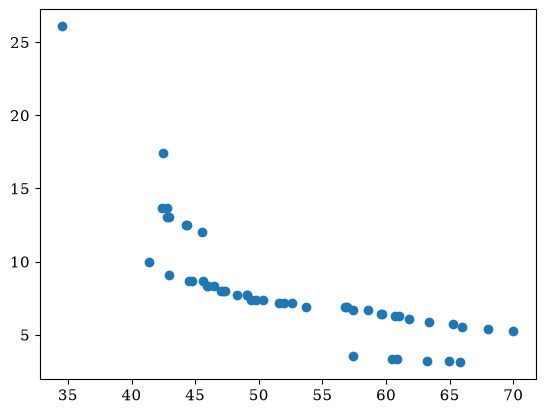

In [189]:
plt.scatter(
    [p.fitness['Total Cost'] / 1e6 for p in population],
    [p.fitness['Fleet Portion'] * 100 for p in population],
)

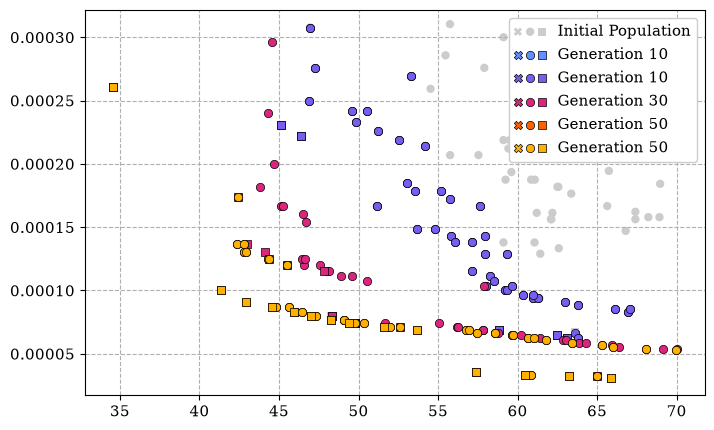

In [193]:
'''
Plotting generations
'''
deep_reload(src)
deep_reload(figures)

fig, ax = plt.subplots(figsize = (8, 5))

show = [10, 100, 300, len(generations) - 1]
show = [10] + list(range(10, len(generations), 20)) + [len(generations) - 1]
# show = list(range(5))

cmap = src.plot.Colormap(
    colors = 'ibm', vmin = 0, vmax = len(show) - 1
)

ax = figures.generations_plot(
    ax, generations, 'Total Cost', 'Fleet Portion',
    interval = 200, rank = 100, cmap = cmap, initial = True,
    show = show,
)

kw = {
    # 'xlabel': 'Capital Cost [Million USD]',
    # 'ylabel': 'Daily Cost [Thousand USD]',
}

_ = ax.set(**kw)

kw = {
    'ls': '--',
}

_ = ax.grid(**kw)

In [191]:
deep_reload(src)
py_pop_dict  = src.optimization.population_to_dict(population)

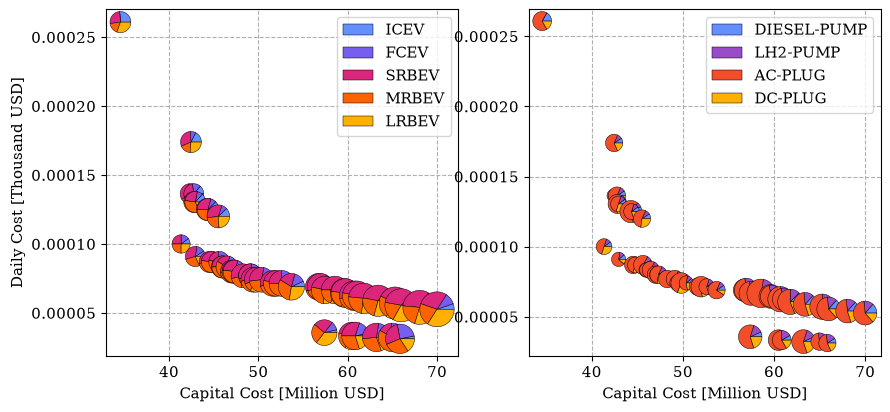

In [192]:
'''
Plotting Pareto Compositions
'''
deep_reload(src)
deep_reload(figures)

matplotlib.rcParams.update(**style['rcparams'])
fig, ax = plt.subplots(1, 2, figsize = (10, 4.5))

n_shown = 100

ax[0] = figures.vehicles_scatter_pie(
    ax[0], py_pop_dict, n_shown = n_shown, size = .04, rank = 100,
    cmap = src.plot.Colormap('ibm'), exponent = 1,
    keys = ['ICEV', 'FCEV', 'SRBEV', 'MRBEV', 'LRBEV'],
)

ax[1] = figures.ports_scatter_pie(
    ax[1], py_pop_dict, n_shown = n_shown, size = .03, rank = 100,
    cmap = src.plot.Colormap('ibm'), exponent = 1,
    keys = ['DIESEL-PUMP', 'LH2-PUMP', 'AC-PLUG', 'DC-PLUG'],
)

kw = {
    'xlabel': 'Capital Cost [Million USD]',
    'ylabel': 'Daily Cost [Thousand USD]',
    # 'xticks': [30, 40, 50, 60, 70, 80, 90],
}

_ = ax[0].set(**kw)

kw = {
    'xlabel': 'Capital Cost [Million USD]',
    # 'xticks': [30, 40, 50, 60, 70, 80, 90],
}

_ = ax[1].set(**kw)

kw = {
    'ls': '--',
}

_ = [ax.grid(**kw) for ax in ax]
_ = [ax.legend() for ax in ax]

In [23]:
# population[0].tours

In [15]:
tours = population[0].tours

edges = [(i, j) for i, s in enumerate(tours) for j, t in enumerate(tours)\
         if t['start'] >= s['finish'] + s['energy'] / 150e3]

len(edges)

1147

In [20]:
101298614.19953549 / 150e3

675.3240946635699

In [5]:
'''
Running the optimization in Python (Not Reccommended) - This will take
    around 30 minutes
'''

t0 = time.perf_counter()

kw = {
    'seed': 460780573,
    'max_iter': 1000,
    'min_iter': 500,
    'initial_population_size': 1500,
    'population_size': 250,
    'crossover_probability': 0.5,
    'mutation_probability': 0.05,
    'survival_threshold': 0,
    'retries': 5,
    'store_interval': 1,
    'same_depot': True,
}

population, generations = network.optimize(**kw)
generations = {i: generations[i] for i in np.sort(list(generations.keys()))}

elapsed = time.perf_counter() - t0
print(f'Done in {elapsed:.1f}s  |  {len(generations)} generations stored')

Generating Initial Population

 [->                   ] 10.60%, 61.97 it/s, 2.60 s elapsed, 21.62 s remaining


KeyboardInterrupt



In [63]:
'''
Making the Rust Network from the Python network
'''
deep_reload(src)

rust_net, index_maps = src.rust_bridge.build_rust_network(network)
print(rust_net.status())

fleet_opt_core.RustNetwork: 973 trips | 81 locations | 1 depots | 3 vehicle types | 3 port types | 2 objectives


In [64]:
'''
Running the optimization in Rust - This will take about one minute
'''

t0 = time.perf_counter()

kw = {
    'seed': 460780573,
    'max_iter': 500,
    'min_iter': 300,
    'initial_population_size': 1500,
    'population_size': 500,
    'crossover_probability': 0.5,
    'mutation_probability': 0.,
    'survival_threshold': 0,
    'retries': 5,
    'store_interval': 1,
    'same_depot': True,
}

population, generations = rust_net.optimize(**kw)
generations = {i: generations[i] for i in np.sort(list(generations.keys()))}

elapsed = time.perf_counter() - t0
print(f'Done in {elapsed:.1f}s  |  {len(generations)} generations stored')

Done in 76.9s  |  501 generations stored


In [10]:
deep_reload(src)

rs_pop_dict = src.rust_bridge.rust_pop_to_python_format(population, index_maps)

py_solutions = src.rust_bridge.resolve_pareto_front(
    network, rs_pop_dict, index_maps, max_solutions = 250, rank = 0,
)
py_pop_dict  = src.optimization.population_to_dict(py_solutions)

NameError: name 'index_maps' is not defined